In [1]:
import requests
import time
from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm import tqdm
import pandas as pd
import os

In [2]:
# Output directory
os.makedirs("Data", exist_ok=True)

# URL for station list
link = 'https://geodesy.unr.edu/NGLStationPages/DataHoldings.txt'
output_path = 'Data/DataHoldings.txt'

# Step 1: Download the station list
response = requests.get(link)
if response.status_code == 200:
    with open(output_path, 'wb') as f:
        f.write(response.content)
    print(f"File downloaded successfully to {output_path}")
else:
    print(f"Failed to download file: Status code {response.status_code}")
    exit()

File downloaded successfully to Data/DataHoldings.txt


In [3]:
# Step 2: Read the station list into DataFrame
df = pd.read_fwf(output_path)
df["Lat"] = df["Lat(deg)"]
df["Lon"] = ((df["Long(deg)"] + 180) % 360) - 180

In [4]:
df

,Sta,Lat(deg),Long(deg),Hgt(m),X(m),Y(m),Z(m),Dtbeg,Dtend,Dtmod,NumSol,StaOrigName,Lat,Lon
0,00NA,-12.4666,130.8440,104.851,-4.073662e+06,4.712065e+06,-1.367875e+06,2008-03-27,2018-09-25,2025-09-25,3185,NaN,-12.4666,130.8440
1,01NA,-12.4782,130.9820,105.409,-4.084823e+06,4.702027e+06,-1.369126e+06,2008-04-08,2019-09-29,2025-09-25,2360,NaN,-12.4782,130.9820
2,02NA,-12.3559,130.8817,117.652,-4.078496e+06,4.711380e+06,-1.355915e+06,2008-09-22,2016-12-31,2025-09-25,1913,NaN,-12.3559,130.8817
3,0ABI,68.3543,18.8164,431.388,2.233557e+06,7.610804e+05,5.906186e+06,2009-06-11,2026-03-28,2026-04-04,5934,NaN,68.3543,18.8164
4,0ABN,65.0337,21.3329,52.762,2.514610e+06,9.820672e+05,5.759344e+06,2023-04-05,2026-03-28,2026-04-04,1061,NaN,65.0337,21.3329
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23485,ZWOL,52.5024,6.0956,86.657,3.868815e+06,4.131543e+05,5.037094e+06,2005-08-02,2008-11-20,2025-09-30,1111,NaN,52.5024,6.0956
23486,ZYRA,52.0548,20.4203,157.400,3.683270e+06,1.371281e+06,5.006677e+06,2014-08-13,2024-10-03,2026-01-10,2831,NaN,52.0548,20.4203
23487,ZYWE,49.6882,19.1974,405.901,3.904715e+06,1.359564e+06,4.840731e+06,2014-04-15,2015-02-21,2025-09-30,283,NaN,49.6882,19.1974
23488,ZYWI,49.6867,19.2060,412.779,3.904633e+06,1.360192e+06,4.840631e+06,2003-07-24,2026-03-21,2026-04-05,7649,NaN,49.6867,19.2060


In [5]:
def filter_by_bbox(df, south, north, west, east,
                   lat_col="Lat", lon_col="Lon"):
    """
    Filter GNSS stations inside a geographic bounding box.

    Parameters
    ----------
    df : pandas.DataFrame
        DataFrame containing latitude and longitude columns.
    south, north : float
        Latitude bounds in degrees (-90 to 90).
    west, east : float
        Longitude bounds in degrees (-180 to 180).
    lat_col : str
        Name of latitude column.
    lon_col : str
        Name of longitude column.

    Returns
    -------
    pandas.DataFrame
        Filtered DataFrame within bounding box.
    """

    # Latitude filter
    lat_mask = (df[lat_col] >= south) & (df[lat_col] <= north)

    # Longitude filter
    if west <= east:
        # Normal case (no dateline crossing)
        lon_mask = (df[lon_col] >= west) & (df[lon_col] <= east)
    else:
        # Dateline crossing case (e.g., west=170, east=-170)
        lon_mask = (df[lon_col] >= west) | (df[lon_col] <= east)

    return df[lat_mask & lon_mask].copy()

In [6]:
s, w = 43.9269,-1.4651
n, e = 45.3186,0.5907

In [7]:
df_filter = filter_by_bbox(df, s, n, w, e, lat_col="Lat", lon_col="Lon")

In [8]:
df_filter

,Sta,Lat(deg),Long(deg),Hgt(m),X(m),Y(m),Z(m),Dtbeg,Dtend,Dtmod,NumSol,StaOrigName,Lat,Lon
686,A147,44.7371,359.2259,114.922,4.537869e+06,-61311.1415,4.466724e+06,2022-03-02,2026-03-21,2026-04-04,1390,NaN,44.7371,-0.7741
694,A164,44.6766,0.1791,159.557,4.543026e+06,14198.1377,4.461973e+06,2022-03-02,2026-03-21,2026-04-04,1364,NaN,44.6766,0.1791
1637,ARES,44.7640,358.8659,64.958,4.535252e+06,-89781.6889,4.468815e+06,2007-07-12,2026-03-28,2026-04-04,5617,NaN,44.7640,-1.1341
1710,ARSE,44.7731,358.8584,61.177,4.534532e+06,-90358.2416,4.469523e+06,2025-07-03,2026-03-28,2026-04-04,269,NaN,44.7731,-1.1416
2105,B216,45.2525,0.3508,125.535,4.497708e+06,27538.6667,4.507237e+06,2025-02-28,2026-03-21,2026-04-04,344,NaN,45.2525,0.3508
2158,B409,44.8322,359.2980,109.049,4.530492e+06,-55510.0962,4.474223e+06,2025-06-04,2026-03-21,2026-04-04,149,NaN,44.8322,-0.7020
2174,B446,44.8698,0.3757,117.457,4.527797e+06,29692.8568,4.477188e+06,2025-07-18,2026-03-21,2026-04-04,225,NaN,44.8698,0.3757
2206,B557,44.4943,359.0441,89.400,4.556578e+06,-76030.8549,4.447503e+06,2025-11-13,2026-03-21,2026-04-04,60,NaN,44.4943,-0.9559
2209,B560,44.7882,359.4226,79.358,4.534032e+06,-45694.6822,4.470727e+06,2025-11-19,2026-03-21,2026-04-04,116,NaN,44.7882,-0.5774
2319,BARD,45.3024,359.9899,155.710,4.493873e+06,-789.7285,4.511161e+06,2015-02-20,2026-03-28,2026-04-04,3906,NaN,45.3024,-0.0101


In [9]:
output_csv = "Data/france_GNSS.csv"
df_filter.to_csv(output_csv, index=True)

In [10]:
df_filter

,Sta,Lat(deg),Long(deg),Hgt(m),X(m),Y(m),Z(m),Dtbeg,Dtend,Dtmod,NumSol,StaOrigName,Lat,Lon
686,A147,44.7371,359.2259,114.922,4.537869e+06,-61311.1415,4.466724e+06,2022-03-02,2026-03-21,2026-04-04,1390,NaN,44.7371,-0.7741
694,A164,44.6766,0.1791,159.557,4.543026e+06,14198.1377,4.461973e+06,2022-03-02,2026-03-21,2026-04-04,1364,NaN,44.6766,0.1791
1637,ARES,44.7640,358.8659,64.958,4.535252e+06,-89781.6889,4.468815e+06,2007-07-12,2026-03-28,2026-04-04,5617,NaN,44.7640,-1.1341
1710,ARSE,44.7731,358.8584,61.177,4.534532e+06,-90358.2416,4.469523e+06,2025-07-03,2026-03-28,2026-04-04,269,NaN,44.7731,-1.1416
2105,B216,45.2525,0.3508,125.535,4.497708e+06,27538.6667,4.507237e+06,2025-02-28,2026-03-21,2026-04-04,344,NaN,45.2525,0.3508
2158,B409,44.8322,359.2980,109.049,4.530492e+06,-55510.0962,4.474223e+06,2025-06-04,2026-03-21,2026-04-04,149,NaN,44.8322,-0.7020
2174,B446,44.8698,0.3757,117.457,4.527797e+06,29692.8568,4.477188e+06,2025-07-18,2026-03-21,2026-04-04,225,NaN,44.8698,0.3757
2206,B557,44.4943,359.0441,89.400,4.556578e+06,-76030.8549,4.447503e+06,2025-11-13,2026-03-21,2026-04-04,60,NaN,44.4943,-0.9559
2209,B560,44.7882,359.4226,79.358,4.534032e+06,-45694.6822,4.470727e+06,2025-11-19,2026-03-21,2026-04-04,116,NaN,44.7882,-0.5774
2319,BARD,45.3024,359.9899,155.710,4.493873e+06,-789.7285,4.511161e+06,2015-02-20,2026-03-28,2026-04-04,3906,NaN,45.3024,-0.0101


In [11]:
import geopandas as gpd
from shapely.geometry import box

def create_bbox_shapefile(south, north, west, east, out_file="bbox.shp"):
    """
    Create a bounding box shapefile from south, north, west, east coordinates.
    Assumes coordinates are in EPSG:4326 (lat/lon).
    """

    # Create rectangular polygon
    geom = box(west, south, east, north)

    # Create GeoDataFrame
    gdf = gpd.GeoDataFrame(
        {"south": [south], "north": [north],
         "west": [west], "east": [east]},
        geometry=[geom],
        crs="EPSG:4326"
    )

    # Save as shapefile
    gdf.to_file(out_file)

    print(f"Bounding box shapefile saved as: {out_file}")

In [12]:
create_bbox_shapefile(
    south=s,
    north=n,
    west=w,
    east=e,
    out_file="Data/france_coast/france_bbox.shp"
)

Bounding box shapefile saved as: Data/france_coast/france_bbox.shp


In [13]:
df = pd.read_csv("Data/france_coast/france_GNSS.csv")

In [25]:
import pandas as pd
import numpy as np

# Read data
file_path = "Data/france_coast/A147.tenv3"
df = pd.read_csv(file_path, sep=r"\s+")

# Time (decimal years)
time = df["yyyy.yyyy"].values

# Vertical displacement (convert m → mm)
up = df["____up(m)"].values * 1000  # mm

# Remove NaNs if any
mask = np.isfinite(time) & np.isfinite(up)
time = time[mask]
up = up[mask]

# Linear fit: up = a*time + b
coeffs = np.polyfit(time, up, 1)

velocity = coeffs[0]   # slope (mm/year)
intercept = coeffs[1]

print(f"Linear velocity: {velocity:.3f} mm/yr")

Linear velocity: -0.861 mm/yr


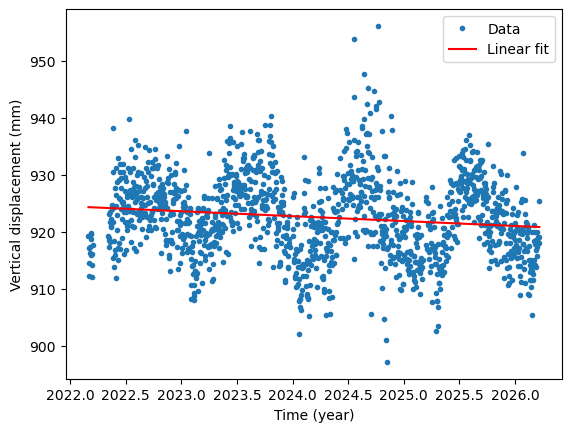

In [26]:
import matplotlib.pyplot as plt

fit_line = velocity * time + intercept

plt.figure()
plt.plot(time, up, '.', label="Data")
plt.plot(time, fit_line, 'r-', label=""Linear velocity: {velocity:.1f} mm/yr"")
plt.xlabel("Time (year)")
plt.ylabel("Vertical displacement (mm)")
plt.legend()
plt.show()

In [29]:
import os
import time
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# Paths
# -----------------------------
DATA_DIR = "Data/france_coast"
PLOT_DIR = f"{DATA_DIR}/pics"
PLOT_PASS = f"{PLOT_DIR}/passed"

os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(PLOT_DIR, exist_ok=True)
os.makedirs(PLOT_PASS, exist_ok=True)

# -----------------------------
# Load station list
# -----------------------------
df_sta = pd.read_csv(f"{DATA_DIR}/france_GNSS.csv")

df_sta["velocity_mm_yr"] = np.nan
df_sta["velocity_filtered_mm_yr"] = np.nan
df_sta["status"] = "Failed"

# -----------------------------
# Download function
# -----------------------------
BASE_URL = "https://geodesy.unr.edu/gps_timeseries/IGS20/tenv3/IGS20/{}.tenv3"

def download_station_file(station):
    filepath = f"{DATA_DIR}/{station}.tenv3"
    if os.path.exists(filepath):
        return filepath

    try:
        r = requests.get(BASE_URL.format(station), timeout=30)
        r.raise_for_status()
        with open(filepath, "wb") as f:
            f.write(r.content)
        return filepath
    except:
        return None

# -----------------------------
# Velocity function
# -----------------------------
def compute_velocity(df):
    time = df["yyyy.yyyy"].values
    up = df["____up(m)"].values * 1000

    mask = np.isfinite(time) & np.isfinite(up)
    if np.sum(mask) < 10:
        return np.nan, None, None, None

    time = time[mask]
    up = up[mask]

    coeffs = np.polyfit(time, up, 1)
    return coeffs[0], time, up, coeffs[1]

# -----------------------------
# Filtering criteria
# -----------------------------
MIN_START = pd.to_datetime("2014-09-01")
MAX_END   = pd.to_datetime("2025-01-01")

# -----------------------------
# Main loop
# -----------------------------
for i, row in df_sta.iterrows():

    station = row["Sta"]
    print(f"Processing: {station}")

    filepath = download_station_file(station)
    if filepath is None:
        continue

    try:
        df = pd.read_csv(filepath, sep=r"\s+")

        # Parse date once
        df["date"] = pd.to_datetime(df["YYMMMDD"], format="%y%b%d")

        # -------------------------
        # FULL velocity (all stations)
        # -------------------------
        vel, t, u, b = compute_velocity(df)
        df_sta.loc[i, "velocity_mm_yr"] = vel

        # Default plot path (failed)
        plot_path = f"{PLOT_DIR}/{station}.png"

        # -------------------------
        # Filtering
        # -------------------------
        start = pd.to_datetime(row["Dtbeg"])
        end   = pd.to_datetime(row["Dtend"])

        if (start <= MIN_START) and (end >= MAX_END):
            df_sta.loc[i, "status"] = "Passed"

            df_filt = df[
                (df["date"] >= MIN_START) &
                (df["date"] <= MAX_END)
            ]

            vel_filt, t_f, u_f, b_f = compute_velocity(df_filt)
            df_sta.loc[i, "velocity_filtered_mm_yr"] = vel_filt

            # Save passed plots separately
            plot_path = f"{PLOT_PASS}/{station}.png"

        else:
            df_sta.loc[i, "status"] = "Failed"
            vel_filt, t_f, u_f, b_f = np.nan, None, None, None

        # -------------------------
        # Plot for ALL stations
        # -------------------------
        # -------------------------
        # Plot for ALL stations
        # -------------------------
        if t is not None:
            plt.figure(figsize=(6,4))
        
            # Full data
            plt.plot(t, u, '.', color='gray', label="Data")
        
            # FULL linear fit (for ALL stations)
            fit_full = vel * t + b
            plt.plot(t, fit_full, 'b-', 
                     label=f"Full: {vel:.2f} mm/yr")
        
            # Filtered fit (ONLY for passed stations)
            if t_f is not None:
                fit_filt = vel_filt * t_f + b_f
                plt.plot(t_f, fit_filt, 'r-', 
                         label=f"Filtered: {vel_filt:.2f} mm/yr")
        
            plt.xlabel("Time (year)")
            plt.ylabel("Up (mm)")
            plt.title(station)
            plt.legend()
        
            plt.savefig(plot_path, dpi=150)
            plt.close()

    except Exception as e:
        print(f"Error with {station}: {e}")
        continue

# -----------------------------
# Save results
# -----------------------------
df_sta.to_csv(f"{DATA_DIR}/france_GNSS_with_velocity.csv", index=False)

print("Done ✅")

Processing: A147
Processing: A164
Processing: ARES
Processing: ARSE
Processing: B216
Processing: B409
Processing: B446
Processing: B557
Processing: B560
Processing: BARD
Processing: BLAN
Processing: BXME
Processing: CAPT
Processing: CDJ2
Processing: CDJC
Processing: CESS
Processing: COUT
Processing: CUBX
Processing: ETAU
Processing: FERR
Processing: FEST
Processing: GAR2
Processing: LAV1
Processing: LBRD
Processing: LCAN
Processing: LCAU
Processing: LGAR
Processing: MIM2
Processing: MZA2
Processing: MZAN
Processing: PESS
Processing: SRMG
Processing: TREN
Done ✅
